# Workshop 3 — Data-Quality Findings of the Bronze and Silver Layers
**Team 4 · Tropical Cyclone Monitoring (TC-Analog Monitor) · Data Analysis Programming**

This notebook audits the data lake produced by the Workshop 2 pipeline with **Pandas** and shows, for every
problem found, the evidence (counts, tables, figures), the improvement made in Workshop 3 and the Gold KPI that
now monitors it. Runs are split into two phases:

* **Workshop 2** — Bronze runs that have no line in `datalake_bronze/_state/ingestion_log_*.jsonl`
  (pipeline as delivered in Workshop 2, 17 Nov 2026);
* **Workshop 3** — runs made after the improvements (they write the ingestion log).

**How to run** (inside the Airflow container, no Python needed on the host):
```bash
docker compose exec airflow-scheduler jupyter nbconvert --to notebook --execute --inplace /opt/airflow/notebooks/03_data_quality_findings.ipynb
```
Figures are also saved to `notebooks/figures/` for the report.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT / "src"))
import os
os.environ.setdefault("TCMON_DATALAKE_ROOT", str(ROOT))
from tcmon.gold import inventory
from tcmon.pipeline import bronze, paths, reference, silver

FIG = ROOT / "notebooks" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
BLUE, ORANGE, GREY, RED = "#2a6f97", "#e07a1f", "#9aa5b1", "#c0392b"

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, bbox_inches="tight"); plt.show()

logged = set()
for src in (bronze.GDACS_SOURCE, bronze.IBTRACS_SOURCE):
    logged |= {r["run_ts"] for r in paths.read_jsonl(bronze.ingestion_log(src))}
phase = lambda ts: "Workshop 3" if ts in logged else "Workshop 2"
print("Data lake:", paths.datalake_root())
print("Runs with an ingestion log (Workshop 3):", len(logged))

Data lake: /opt/airflow
Runs with an ingestion log (Workshop 3): 17


## 0. Inventory of the lake
One row per Bronze file (envelope header only) and one row per Silver run (`_manifest.jsonl`).

In [2]:
brz = pd.DataFrame(inventory.bronze_inventory())
brz["phase"] = brz["run_ts"].map(phase)
brz["delay_min"] = (brz["ingested_at_utc"] - brz["run_time_utc"]).dt.total_seconds() / 60
man = pd.DataFrame(inventory.silver_manifest())
man["phase"] = np.where(man["fence_basis"] == "batch (Workshop 2)", "Workshop 2", "Workshop 3")   # W3 lines record their fences
print(f"Bronze files: {len(brz)}  |  Silver runs: {len(man)}  |  Silver files on disk: {len(list(paths.silver_dir().glob('tropical_cyclones_*.parquet')))}")
brz[["phase", "source", "file", "ingested_at_utc", "record_count", "file_bytes", "etag", "delay_min"]]

Bronze files: 45  |  Silver runs: 27  |  Silver files on disk: 22


,phase,source,file,ingested_at_utc,record_count,file_bytes,etag,delay_min
0,Workshop 2,gdacs_tc,gdacs_tc_20261117_010000.json,2026-11-17 02:03:47+00:00,4,8205,None,63.783333
1,Workshop 2,gdacs_tc,gdacs_tc_20261117_020244.json,2026-11-17 02:04:55+00:00,4,8204,None,2.183333
2,Workshop 2,gdacs_tc,gdacs_tc_20261117_021437.json,2026-11-17 02:15:37+00:00,4,8205,None,1.000000
3,Workshop 2,gdacs_tc,gdacs_tc_20261117_021900.json,2026-11-17 02:19:52+00:00,4,8205,None,0.866667
4,Workshop 2,gdacs_tc,gdacs_tc_20261117_220000.json,2026-11-17 23:53:32+00:00,4,7936,None,113.533333
5,Workshop 2,gdacs_tc,gdacs_tc_20261117_230000.json,2026-11-18 00:04:37+00:00,4,7936,None,64.616667
6,Workshop 2,gdacs_tc,gdacs_tc_20261117_235429.json,2026-11-17 23:54:43+00:00,4,7936,None,0.233333
7,Workshop 2,gdacs_tc,gdacs_tc_20261118_000000.json,2026-11-18 01:03:39+00:00,4,7935,None,63.650000
8,Workshop 2,gdacs_tc,gdacs_tc_20261118_010000.json,2026-11-18 02:02:56+00:00,4,7936,None,62.933333
9,Workshop 2,gdacs_tc,gdacs_tc_20261118_020000.json,2026-11-18 03:04:42+00:00,4,7936,None,64.700000


In [3]:
man[["phase", "silver_run_ts", "silver_file", "processed_at_utc", "bronze_files", "input", "cross_batch_duplicates",
     "revisions", "rows", "rejected", "fence_basis"]]

,phase,silver_run_ts,silver_file,processed_at_utc,bronze_files,input,cross_batch_duplicates,revisions,rows,rejected,fence_basis
0,Workshop 2,20261117_014500,tropical_cyclones_20261117_014500.parquet,2026-11-17 02:05:04+00:00,2,147,0,0,147,0,batch (Workshop 2)
1,Workshop 2,20261117_020252,tropical_cyclones_20261117_020252.parquet,2026-11-17 02:05:41+00:00,2,147,147,0,0,0,batch (Workshop 2)
2,Workshop 2,20261117_020000,tropical_cyclones_20261117_020000.parquet,2026-11-17 02:16:46+00:00,2,147,146,1,1,0,batch (Workshop 2)
3,Workshop 2,20261117_021504,tropical_cyclones_20261117_021504.parquet,2026-11-17 02:20:29+00:00,2,147,147,0,0,0,batch (Workshop 2)
4,Workshop 2,20261117_233000,tropical_cyclones_20261117_233000.parquet,2026-11-17 23:54:34+00:00,2,146,126,0,20,0,batch (Workshop 2)
5,Workshop 2,20261117_235520,tropical_cyclones_20261117_235520.parquet,2026-11-17 23:55:29+00:00,2,146,146,0,0,0,batch (Workshop 2)
6,Workshop 2,20261117_234500,tropical_cyclones_20261117_234500.parquet,2026-11-18 00:05:18+00:00,2,146,146,0,0,0,batch (Workshop 2)
7,Workshop 2,20261118_004500,tropical_cyclones_20261118_004500.parquet,2026-11-18 01:04:18+00:00,2,146,146,0,0,0,batch (Workshop 2)
8,Workshop 2,20261118_014500,tropical_cyclones_20261118_014500.parquet,2026-11-18 02:03:42+00:00,2,146,145,0,1,0,batch (Workshop 2)
9,Workshop 2,20261118_024500,tropical_cyclones_20261118_024500.parquet,2026-11-18 03:05:23+00:00,2,146,146,0,0,0,batch (Workshop 2)


## F1. GDACS answers HTTP 400 "Execution Timeout Expired"
A query to the GDACS event API that times out on the server side comes back as **HTTP 400** (a client-error code)
with a JSON message, after about 38 s. The Workshop 2 client retried only 429 and 5xx, so the run lost its GDACS
file, and the error body stayed in `_staging/`.

In [4]:
att = pd.DataFrame(inventory.attempts())
att["phase"] = att["run_ts"].map(phase)
fails = att[att.outcome == "failed"]
print(att.groupby(["phase", "source", "outcome"]).size().unstack(fill_value=0))
for folder in (paths.staging_dir(), paths.errors_dir()):
    for f in sorted(folder.glob("*.http*")):
        if f.name.endswith(".meta.json"):
            continue
        meta = paths.read_json(Path(str(f) + ".meta.json"), {}) or {}
        print(f"\n{folder.name}/{f.name}\n  requested {meta.get('requested_at_utc')}  status {meta.get('status')}  "
              f"elapsed {meta.get('elapsed_s')} s\n  url {meta.get('url')}\n  body {f.read_text()[:200]}")
fails

outcome                    failed  not_modified  stored
phase      source                                      
Workshop 2 gdacs_tc             5             0      13
           ibtracs_active       0             0      13
Workshop 3 gdacs_tc             0             0      17
           ibtracs_active       0            15       2

_errors/gdacs_tc_20261117_230000_p01.json.http400
  requested 2026-11-18T00:00:04Z  status 400  elapsed 38.011 s
  url https://www.gdacs.org/gdacsapi/api/events/geteventlist/SEARCH?eventlist=TC&fromdate=2026-11-10&todate=2026-11-17&alertlevel=green%3Borange%3Bred&pagenumber=1
  body {"message":"Execution Timeout Expired.  The timeout period elapsed prior to completion of the operation or the server is not responding."}

_errors/gdacs_tc_20261118_000000_p01.json.http400
  requested 2026-11-18T01:00:04Z  status 400  elapsed 33.441 s
  url https://www.gdacs.org/gdacsapi/api/events/geteventlist/SEARCH?eventlist=TC&fromdate=2026-11-11&todate=2026-11-18&alertle

,source,run_ts,run_time_utc,outcome,bytes,elapsed_s,http_status,origin,phase
60,gdacs_tc,20261117_230000,2026-11-17 23:00:00+00:00,failed,138,38.011,400,_errors/,Workshop 2
61,gdacs_tc,20261118_000000,2026-11-18 00:00:00+00:00,failed,138,33.441,400,_errors/,Workshop 2
62,gdacs_tc,20261118_010000,2026-11-18 01:00:00+00:00,failed,138,31.750,400,_errors/,Workshop 2
63,gdacs_tc,20261118_020000,2026-11-18 02:00:00+00:00,failed,138,33.617,400,_errors/,Workshop 2
64,gdacs_tc,20261118_030000,2026-11-18 03:00:00+00:00,failed,138,38.817,400,_errors/,Workshop 2


**Improvement.** The HTTP client now treats a short 400 body containing "timeout" as transient and retries it
(4 s, 8 s, 16 s back-off) on top of the task retries; when a source still fails, its error body is moved to
`datalake_bronze/_errors/` and the attempt is written to the ingestion log. **KPI:** C3 (extraction success rate).

## F2. IBTrACS ACTIVE is downloaded and stored every hour although it changes about three times a week

,files,distinct_contents,redundant,MB_stored,MB_redundant
phase,,,,,
Workshop 2,13,2,11,7.53,6.36
Workshop 3,2,2,1,0.81,0.57


,phase,file,etag,last_modified,record_count,file_bytes,same_as_previous
30,Workshop 2,ibtracs_active_20261117_010000.json,"""10da9-6604dc9641a49""","Sun, 15 Nov 2026 10:04:27 GMT",143,599678,False
31,Workshop 2,ibtracs_active_20261117_020244.json,"""10da9-6604dc9641a49""","Sun, 15 Nov 2026 10:04:27 GMT",143,599678,True
32,Workshop 2,ibtracs_active_20261117_021437.json,"""10da9-6604dc9641a49""","Sun, 15 Nov 2026 10:04:27 GMT",143,599678,True
33,Workshop 2,ibtracs_active_20261117_021900.json,"""10da9-6604dc9641a49""","Sun, 15 Nov 2026 10:04:27 GMT",143,599678,True
34,Workshop 2,ibtracs_active_20261117_220000.json,"""10c15-6607619c2acbb""","Tue, 17 Nov 2026 10:10:14 GMT",142,570221,False
35,Workshop 2,ibtracs_active_20261117_230000.json,"""10c15-6607619c2acbb""","Tue, 17 Nov 2026 10:10:14 GMT",142,570221,True
36,Workshop 2,ibtracs_active_20261117_235429.json,"""10c15-6607619c2acbb""","Tue, 17 Nov 2026 10:10:14 GMT",142,570221,True
37,Workshop 2,ibtracs_active_20261118_000000.json,"""10c15-6607619c2acbb""","Tue, 17 Nov 2026 10:10:14 GMT",142,570221,True
38,Workshop 2,ibtracs_active_20261118_010000.json,"""10c15-6607619c2acbb""","Tue, 17 Nov 2026 10:10:14 GMT",142,570221,True
39,Workshop 2,ibtracs_active_20261118_020000.json,"""10c15-6607619c2acbb""","Tue, 17 Nov 2026 10:10:14 GMT",142,570220,True


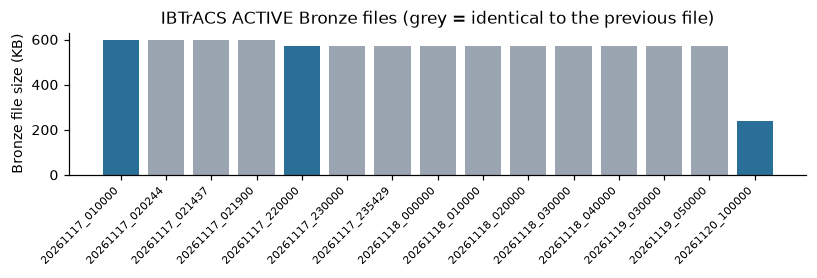

Workshop 2 behaviour: ~13.7 MB/day of Bronze JSON, ~5.0 GB/year, almost all duplicates

Workshop 3 attempts by outcome: {'not_modified': 15, 'stored': 2}


In [5]:
ib = brz[brz.source == "ibtracs_active"].sort_values("run_time_utc").copy()
ib["same_as_previous"] = ib["sha256"].eq(ib["sha256"].shift()) & ib["sha256"].ne("")
summary = ib.groupby("phase").agg(files=("file", "size"), distinct_contents=("sha256", "nunique"),
                                  redundant=("same_as_previous", "sum"),
                                  MB_stored=("file_bytes", lambda s: round(s.sum() / 1e6, 2)))
summary["MB_redundant"] = ib[ib.same_as_previous].groupby("phase")["file_bytes"].sum().div(1e6).round(2)
display(summary.fillna(0))
display(ib[["phase", "file", "etag", "last_modified", "record_count", "file_bytes", "same_as_previous"]])
fig, ax = plt.subplots(figsize=(7.5, 2.6))
ax.bar(range(len(ib)), ib["file_bytes"] / 1e3, color=[GREY if r else BLUE for r in ib["same_as_previous"]])
ax.set_xticks(range(len(ib)), ib["run_ts"], rotation=45, ha="right", fontsize=7)
ax.set_ylabel("Bronze file size (KB)")
ax.set_title("IBTrACS ACTIVE Bronze files (grey = identical to the previous file)")
save(fig, "f2_ibtracs_redundant.png")
per_day = 24 * ib["file_bytes"].median() / 1e6
print(f"Workshop 2 behaviour: ~{per_day:.1f} MB/day of Bronze JSON, ~{per_day * 365 / 1e3:.1f} GB/year, almost all duplicates")
ib_log = att[(att.source == "ibtracs_active") & (att.origin == "ingestion_log")]
print("\nWorkshop 3 attempts by outcome:", ib_log["outcome"].value_counts().to_dict() or "no Workshop 3 run yet")

**Improvement.** Conditional GET with the stored `ETag` / `Last-Modified` (and a SHA-256 comparison when the server
answers 200 anyway). An unchanged file produces no Bronze file and no Silver work; the Bronze run is still complete.
**KPIs:** E1 (identical consecutive files), E2 (answers "not modified"), U1 (cross-batch duplicate rate).

## F3. File timestamps did not match the moment of ingestion
Workshop 2 named files with Airflow's `logical_date`. For a scheduled run that is the **start** of the data interval,
so the hourly run that actually started at 23:53 was stored as `..._220000`, and a Silver file could carry an earlier
timestamp than the Bronze file it processed.

count     min     50%     max
phase      source                                       
Workshop 2 gdacs_tc         13.0     0.2    63.6  1443.7
           ibtracs_active   13.0     0.2    60.2  1443.6
Workshop 3 gdacs_tc         17.0     0.6     1.2  1074.1
           ibtracs_active    2.0  1019.5  1046.8  1074.2

,phase,silver_run_ts,newest_bronze_time_utc,processed_at_utc,silver_named_before_input
0,Workshop 2,20261117_014500,2026-11-17 01:00:00+00:00,2026-11-17 02:05:04+00:00,False
1,Workshop 2,20261117_020252,2026-11-17 02:02:44+00:00,2026-11-17 02:05:41+00:00,False
2,Workshop 2,20261117_020000,2026-11-17 02:14:37+00:00,2026-11-17 02:16:46+00:00,True
3,Workshop 2,20261117_021504,2026-11-17 02:19:00+00:00,2026-11-17 02:20:29+00:00,True
4,Workshop 2,20261117_233000,2026-11-17 22:00:00+00:00,2026-11-17 23:54:34+00:00,False
5,Workshop 2,20261117_235520,2026-11-17 23:54:29+00:00,2026-11-17 23:55:29+00:00,False
6,Workshop 2,20261117_234500,2026-11-17 23:00:00+00:00,2026-11-18 00:05:18+00:00,False
7,Workshop 2,20261118_004500,2026-11-18 00:00:00+00:00,2026-11-18 01:04:18+00:00,False
8,Workshop 2,20261118_014500,2026-11-18 01:00:00+00:00,2026-11-18 02:03:42+00:00,False
9,Workshop 2,20261118_024500,2026-11-18 02:00:00+00:00,2026-11-18 03:05:23+00:00,False


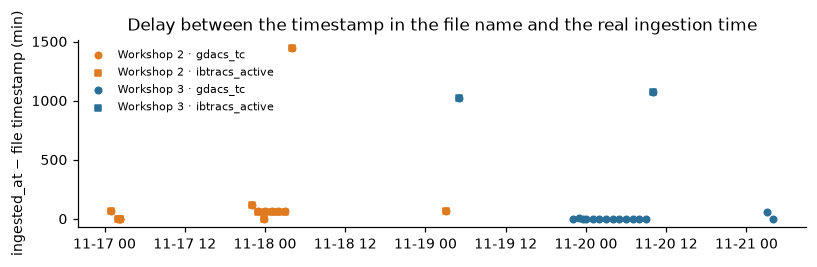

In [6]:
display(brz.groupby(["phase", "source"])["delay_min"].describe()[["count", "min", "50%", "max"]].round(1))
lin = man.dropna(subset=["newest_bronze_time_utc"]).copy()
lin["silver_named_before_input"] = lin["run_time_utc"] < lin["newest_bronze_time_utc"]
display(lin[["phase", "silver_run_ts", "newest_bronze_time_utc", "processed_at_utc", "silver_named_before_input"]])
fig, ax = plt.subplots(figsize=(7.5, 2.4))
for (ph, src), g in brz.groupby(["phase", "source"]):
    ax.scatter(g["run_time_utc"], g["delay_min"], s=18, label=f"{ph} · {src}",
               color=BLUE if ph == "Workshop 3" else ORANGE, marker="o" if src.startswith("gdacs") else "s")
ax.set_ylabel("ingested_at − file timestamp (min)"); ax.legend(fontsize=7, frameon=False)
ax.set_title("Delay between the timestamp in the file name and the real ingestion time")
save(fig, "f3_timestamp_delay.png")

**Improvement.** Scheduled runs are now named with `data_interval_end` (the moment the run starts), manual runs with
the trigger time; the same rule is used by Bronze, Silver and Gold. **KPIs:** T1 (delay), F5 (Silver named before its input).

## F4. Half of the Silver files were empty

In [7]:
files = pd.DataFrame([{"file": f.name, "KB": round(f.stat().st_size / 1024, 1)} for f in sorted(paths.silver_dir().glob("tropical_cyclones_*.parquet"))])
display(man.groupby("phase").agg(runs=("silver_run_ts", "size"), runs_without_new_rows=("rows", lambda s: int((s == 0).sum())),
                                 files_written=("silver_file", lambda s: int(s.notna().sum()))))
print(f"Empty files still on disk from Workshop 2: {int(((man.rows == 0) & man.silver_file.notna()).sum())} "
      f"(each ~{files['KB'].min() if len(files) else 0} KB of schema and metadata)")

,runs,runs_without_new_rows,files_written
phase,,,
Workshop 2,12,7,12
Workshop 3,15,5,10


Empty files still on disk from Workshop 2: 7 (each ~18.9 KB of schema and metadata)


**Improvement.** A batch without new or changed records writes no Parquet file; the run is still recorded in
`_manifest.jsonl` (`silver_file = null`). **KPI:** F4 (empty Silver files).

## F5. Duplicates and revisions across batches
Silver keeps one row per (`event_id`, `record_hash`); a changed record of a known event is kept as a revision.

/tmp/ipykernel_4469/1760527525.py:2: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  allv = pd.concat([pd.read_parquet(f) for f in silver_files], ignore_index=True)


Silver rows (all versions): 231  |  distinct events: 215  |  revisions: 16


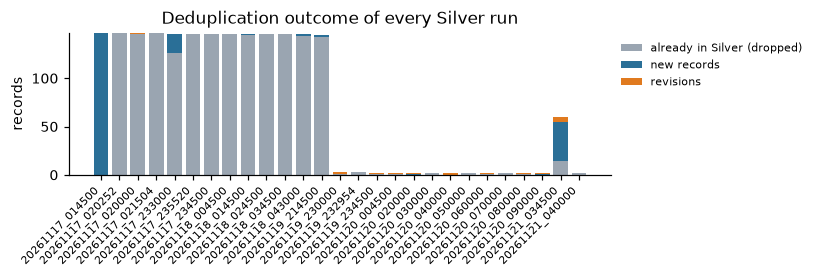

,event_id,source,storm_name,gdacs_episode_id,alert_level,alert_score,date_modified_utc,silver_run_ts,is_revision
150,45e1068114f8cc55c043b83efba24c0b6b72e305,ibtracs_active,AKVAN,<NA>,NaN,NaN,NaT,20261117_233000,False
197,45e1068114f8cc55c043b83efba24c0b6b72e305,ibtracs_active,AKVAN,<NA>,NaN,NaN,NaT,20261121_034500,True
171,515fbbbc8715bfd436416e07168cc0e824253065,gdacs_tc,XAVIER,10,Green,1.0,2026-11-19 20:06:00+00:00,20261119_214500,False
173,515fbbbc8715bfd436416e07168cc0e824253065,gdacs_tc,XAVIER,10,Green,1.0,2026-11-19 22:05:06+00:00,20261119_230000,True
51,5ac55dd92e59f0ecd209c0b03211aa15e9ccb8eb,gdacs_tc,AKVAN,1,Orange,2.0,2026-11-17 01:20:29+00:00,20261117_014500,False
147,5ac55dd92e59f0ecd209c0b03211aa15e9ccb8eb,gdacs_tc,AKVAN,1,Orange,2.0,2026-11-17 02:05:47+00:00,20261117_020000,True
161,ca540653d900257001b5a0fb8d22e5ac209fefbd,ibtracs_active,AKVAN,<NA>,NaN,NaN,NaT,20261117_233000,False
218,ca540653d900257001b5a0fb8d22e5ac209fefbd,ibtracs_active,AKVAN,<NA>,NaN,NaN,NaT,20261121_034500,True
162,d39b07cd8b707f075ae3d3202875330b2fef71a2,ibtracs_active,XAVIER,<NA>,NaN,NaN,NaT,20261117_233000,False
220,d39b07cd8b707f075ae3d3202875330b2fef71a2,ibtracs_active,XAVIER,<NA>,NaN,NaN,NaT,20261121_034500,True


In [8]:
silver_files = sorted(paths.silver_dir().glob("tropical_cyclones_*.parquet"))
allv = pd.concat([pd.read_parquet(f) for f in silver_files], ignore_index=True)
latest = allv.sort_values(["processed_at_utc", "silver_run_ts"]).drop_duplicates("event_id", keep="last")
print(f"Silver rows (all versions): {len(allv)}  |  distinct events: {allv.event_id.nunique()}  |  revisions: {int(allv.is_revision.sum())}")
d = man.set_index("silver_run_ts")[["cross_batch_duplicates", "revisions", "rows"]].copy()
d["new"] = d["rows"] - d["revisions"]
fig, ax = plt.subplots(figsize=(7.5, 2.6))
ax.bar(d.index, d["cross_batch_duplicates"], color=GREY, label="already in Silver (dropped)")
ax.bar(d.index, d["new"], bottom=d["cross_batch_duplicates"], color=BLUE, label="new records")
ax.bar(d.index, d["revisions"], bottom=d["cross_batch_duplicates"] + d["new"], color=ORANGE, label="revisions")
ax.set_xticks(range(len(d)), d.index, rotation=45, ha="right", fontsize=7); ax.set_ylabel("records")
ax.legend(fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title("Deduplication outcome of every Silver run")
save(fig, "f5_dedup.png")
rev_ids = allv.loc[allv.is_revision, "event_id"]
cols = ["event_id", "source", "storm_name", "gdacs_episode_id", "alert_level", "alert_score", "date_modified_utc",
        "silver_run_ts", "is_revision"]
allv[allv.event_id.isin(rev_ids)].sort_values(["event_id", "processed_at_utc"])[cols]

**Reading.** The revision is a GDACS episode whose `datemodified` changed between two polls: the source edits
records in place, so the Gold layer reads only the **latest version** of each `event_id`. **KPIs:** U1–U4.

## F6. The batch IQR rule flagged a real typhoon peak as an outlier
Workshop 2 flagged `wind_kt` outside [Q1 − 1.5·IQR, Q3 + 1.5·IQR] **of each batch**. The fences therefore moved with the
storms present in the batch. Below, every Bronze batch is preprocessed again with the Workshop 2 rule and with the
Workshop 3 rule (6-hourly intensity change against the 1980–2025 climatology, 3·IQR; speed z-score against the
climatological mean and SD).

In [9]:
def w2_wind_flags(df):
    w = df["wind_kt"].dropna()
    if len(w) < 8:
        return pd.Series(False, index=df.index)
    q1, q3 = w.quantile([0.25, 0.75]); iqr = q3 - q1
    return df["wind_kt"].notna() & ~df["wind_kt"].between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

def w2_speed_flags(df):
    s = df["storm_speed_kt"].dropna()
    if len(s) < 8 or s.std(ddof=0) == 0:
        return pd.Series(False, index=df.index)
    return ((df["storm_speed_kt"] - s.mean()) / s.std(ddof=0)).abs() > 3

ref_stats = silver.reference_stats()
print("Climatological fences:", "available" if ref_stats else "NOT built yet (run gold_processing or python -m tcmon.pipeline.reference)")
if ref_stats:
    q1, q3 = ref_stats["dwind6_q1"], ref_stats["dwind6_q3"]
    print(f"  6-h wind change: Q1 {q1:+.1f}, Q3 {q3:+.1f} kt -> fence [{q1 - 3*(q3-q1):+.1f}, {q3 + 3*(q3-q1):+.1f}] kt/6 h "
          f"({ref_stats['dwind6_n']:,} changes, {ref_stats['storms']:,} storms)")
    print(f"  speed: mean {ref_stats['speed_mean']:.1f} kt, SD {ref_stats['speed_std']:.1f} kt -> |z| > 3 above "
          f"{ref_stats['speed_mean'] + 3*ref_stats['speed_std']:.1f} kt")
rows, kept = [], {}
for run in sorted(brz["run_ts"].unique()):
    frames = []
    for b in brz[brz.run_ts == run].itertuples():
        env = json.loads((paths.bronze_dir() / b.file).read_text(encoding="utf-8"))
        frames.append((silver.conform_ibtracs if b.source.startswith("ibtracs") else silver.conform_gdacs)(env, b.file))
    frames = [f for f in frames if len(f)]
    if not frames:
        continue
    c, _ = silver.clean(pd.concat(frames, ignore_index=True))
    fx = c[c.event_type == "tc_track_fix"]
    if fx.empty:
        continue
    rows.append({"bronze_run": run, "phase": phase(run), "track_fixes": len(fx),
                 "W2_wind_IQR_flags": int(w2_wind_flags(fx).sum()), "W3_wind_change_flags": int(fx.wind_iqr_outlier.sum()),
                 "W2_speed_z_flags": int(w2_speed_flags(fx).sum()), "W3_speed_z_flags": int(fx.speed_zscore_outlier.sum()),
                 "W3_fence_basis": c.attrs["outlier_fences"]["basis"]})
    kept[run] = fx.assign(w2_flag=w2_wind_flags(fx))
cmp_ = pd.DataFrame(rows)
cmp_

Climatological fences: available
  6-h wind change: Q1 +0.0, Q3 +5.0 kt -> fence [-15.0, +20.0] kt/6 h (132,850 changes, 5,019 storms)
  speed: mean 10.0 kt, SD 6.7 kt -> |z| > 3 above 30.0 kt


,bronze_run,phase,track_fixes,W2_wind_IQR_flags,W3_wind_change_flags,W2_speed_z_flags,W3_speed_z_flags,W3_fence_basis
0,20261117_010000,Workshop 2,143,16,0,4,4,reference
1,20261117_020244,Workshop 2,143,16,0,4,4,reference
2,20261117_021437,Workshop 2,143,16,0,4,4,reference
3,20261117_021900,Workshop 2,143,16,0,4,4,reference
4,20261117_220000,Workshop 2,142,0,2,4,4,reference
5,20261117_230000,Workshop 2,142,0,2,4,4,reference
6,20261117_235429,Workshop 2,142,0,2,4,4,reference
7,20261118_000000,Workshop 2,142,0,2,4,4,reference
8,20261118_010000,Workshop 2,142,0,2,4,4,reference
9,20261118_020000,Workshop 2,142,0,2,4,4,reference


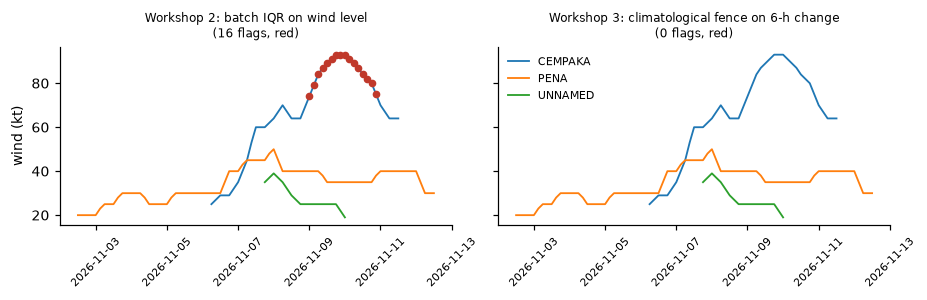

In [10]:
if kept:
    run = max(kept, key=lambda r: kept[r]["w2_flag"].sum())
    fx = kept[run]
    fig, axes = plt.subplots(1, 2, figsize=(8.5, 2.8), sharey=True)
    for ax, flag, title in ((axes[0], "w2_flag", "Workshop 2: batch IQR on wind level"),
                            (axes[1], "wind_iqr_outlier", "Workshop 3: climatological fence on 6-h change")):
        for name, g in fx.assign(storm_name=fx.storm_name.fillna("UNNAMED")).groupby("storm_name"):
            g = g.sort_values("timestamp_utc")
            ax.plot(g["timestamp_utc"], g["wind_kt"], lw=1.2, label=str(name))
            ax.scatter(g.loc[g[flag], "timestamp_utc"], g.loc[g[flag], "wind_kt"], color=RED, s=16, zorder=3)
        ax.set_title(f"{title}\n({int(fx[flag].sum())} flags, red)", fontsize=8); ax.tick_params(axis="x", labelrotation=45, labelsize=7)
    axes[0].set_ylabel("wind (kt)"); axes[1].legend(fontsize=7, frameon=False)
    save(fig, "f6_outlier_rule.png")

**Reading.** With the batch rule, whether a 90 kt typhoon fix is an "outlier" depended on which other storms were in
the batch. The new rule flags only unusually fast intensity changes and unusually fast motion relative to 45 years of
history; values are never changed, only flagged. **KPIs:** V4, V5, V9.

## F7. Completeness by source and field
Nulls in Silver are mostly **structural**: GDACS publishes a peak wind but no current wind, pressure or motion, and
IBTrACS has no alert fields. The table separates structural from real gaps.

source,gdacs_tc,ibtracs_active
storm_name,0.0,9.5
wind_kt,100.0,0.0
sshs_category,100.0,0.0
pressure_hpa,100.0,3.0
peak_wind_kt,0.0,100.0
nature,100.0,0.0
track_type,100.0,0.0
storm_speed_kt,100.0,0.0
storm_dir_deg,100.0,0.0
dist2land_km,100.0,0.0


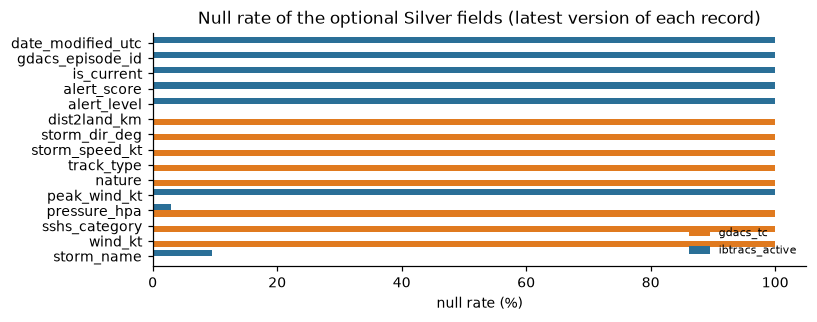

Real gaps in IBTrACS fixes: wind 0.0%, pressure 3.0%, motion derived from fixes 0.0%, provisional 100%


In [11]:
optional = [c for c in latest.columns if latest[c].isna().any()]
nulls = (latest.groupby("source", observed=True)[optional].apply(lambda g: g.isna().mean() * 100)).T.round(1)
display(nulls)
fig, ax = plt.subplots(figsize=(7.5, 3.0))
nulls.plot.barh(ax=ax, color=[ORANGE, BLUE][:nulls.shape[1]], width=0.8)
ax.set_xlabel("null rate (%)"); ax.set_title("Null rate of the optional Silver fields (latest version of each record)")
ax.legend(fontsize=7, frameon=False)
save(fig, "f7_null_rates.png")
fx_all = latest[latest.event_type == "tc_track_fix"]
print(f"Real gaps in IBTrACS fixes: wind {fx_all.wind_kt.isna().mean():.1%}, pressure {fx_all.pressure_hpa.isna().mean():.1%}, "
      f"motion derived from fixes {fx_all.motion_derived.mean():.1%}, provisional {fx_all.is_provisional.mean():.0%}")

## F8. The two sources disagree on intensity and are not equally fresh

,ibtracs_max_kt,ibtracs_last,basin,gdacs_peak_kt,gdacs_last,episodes,alert,peak_diff_kt,gdacs_lead_h
storm_name,,,,,,,,,
AKVAN,45.0,2026-11-19 12:00:00+00:00,NI,49.995680,2026-11-19 18:00:00+00:00,5,Green,5.0,6.0
CEMPAKA,93.0,2026-11-11 12:00:00+00:00,WP,94.991793,2026-11-11 12:00:00+00:00,1,Green,2.0,0.0
PENA,50.0,2026-11-12 12:00:00+00:00,EP,49.995680,2026-11-12 15:00:00+00:00,1,Green,-0.0,3.0
XAVIER,128.0,2026-11-19 12:00:00+00:00,SP,129.988769,2026-11-21 00:00:00+00:00,7,Green,2.0,36.0


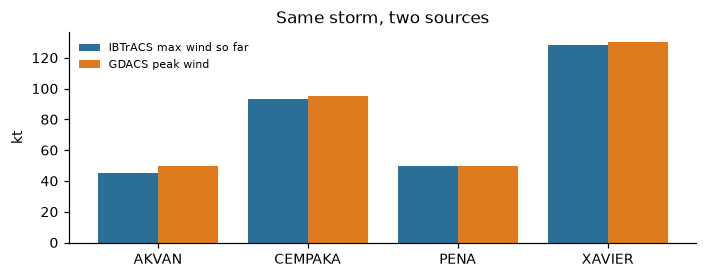

In [12]:
ibm = latest[(latest.source == "ibtracs_active") & latest.storm_name.notna()].groupby("storm_name").agg(
    ibtracs_max_kt=("wind_kt", "max"), ibtracs_last=("timestamp_utc", "max"), basin=("basin", "first"))
gdm = latest[(latest.source == "gdacs_tc") & latest.storm_name.notna()].groupby("storm_name").agg(
    gdacs_peak_kt=("peak_wind_kt", "max"), gdacs_last=("timestamp_utc", "max"), episodes=("gdacs_episode_id", "nunique"),
    alert=("alert_level", "last"))
both = ibm.join(gdm, how="outer")
both["peak_diff_kt"] = (both["gdacs_peak_kt"] - both["ibtracs_max_kt"]).round(1)
both["gdacs_lead_h"] = (both["gdacs_last"] - both["ibtracs_last"]).dt.total_seconds() / 3600
display(both)
fig, ax = plt.subplots(figsize=(6.5, 2.6))
x = np.arange(len(both))
ax.bar(x - 0.2, both["ibtracs_max_kt"], 0.4, color=BLUE, label="IBTrACS max wind so far")
ax.bar(x + 0.2, both["gdacs_peak_kt"], 0.4, color=ORANGE, label="GDACS peak wind")
ax.set_xticks(x, both.index); ax.set_ylabel("kt"); ax.legend(fontsize=7, frameon=False)
ax.set_title("Same storm, two sources")
save(fig, "f8_sources.png")

**Reading.** GDACS is updated several hours ahead of the IBTrACS ACTIVE file, so for a strengthening storm its peak
is higher simply because it is more recent. The Gold layer reports both, with the lag, instead of choosing one.
**KPIs:** K1 (peak difference), K2 (lead time), K3 (storms in both sources), T3 (age of newest observation).

## F9. Storm names

In [13]:
nm = latest[["source", "storm_name_raw", "storm_name", "is_unnamed"]].drop_duplicates()
nm["len_raw"], nm["len_norm"] = nm.storm_name_raw.str.len(), nm.storm_name.str.len()
display(nm.sort_values(["source", "storm_name"]))
display(nm.groupby("source")[["len_raw", "len_norm"]].mean().round(1))

,source,storm_name_raw,storm_name,is_unnamed,len_raw,len_norm
147,gdacs_tc,Tropical Cyclone AKVAN-26,AKVAN,False,25,5
16,gdacs_tc,Tropical Cyclone CEMPAKA-26,CEMPAKA,False,27,7
25,gdacs_tc,Tropical Cyclone PENA-26,PENA,False,24,4
44,gdacs_tc,Tropical Cyclone XAVIER-26,XAVIER,False,26,6
186,ibtracs_active,AKVAN,AKVAN,False,5,5
9,ibtracs_active,CEMPAKA,CEMPAKA,False,7,7
0,ibtracs_active,PENA,PENA,False,4,4
148,ibtracs_active,XAVIER,XAVIER,False,6,6
3,ibtracs_active,UNNAMED,<NA>,True,7,<NA>


,len_raw,len_norm
source,,
gdacs_tc,25.5,5.5
ibtracs_active,5.8,5.5


## Summary of findings → improvements → KPIs

In [14]:
pd.DataFrame([
    ["F1", "GDACS HTTP 400 'Execution Timeout' after ~38 s; run lost its GDACS file; error body left in _staging/",
     "retry transient 400; quarantine error bodies; ingestion log", "C3"],
    ["F2", "IBTrACS ACTIVE stored every hour although unchanged", "conditional GET + SHA-256; no file when unchanged", "E1, E2, U1"],
    ["F3", "file timestamps = start of the data interval (up to ~2 h before ingestion)", "data_interval_end for scheduled runs", "T1, F5"],
    ["F4", "0-row Silver files for batches without changes", "no file; manifest line only", "F4"],
    ["F5", "GDACS edits records in place (revisions)", "Gold reads the latest version of each event", "U3, U4"],
    ["F6", "batch IQR flagged real typhoon peaks; fences moved with the batch", "climatological fences on 6-h change and speed", "V4, V5, V9"],
    ["F7", "structural nulls by source; provisional fixes", "null rate per source/field; provisional share", "C1, V3, V7"],
    ["F8", "GDACS ahead of IBTrACS; peaks differ", "both kept with lead time", "K1, K2, K3, T3"],
    ["F9", "names with prefixes/suffixes and placeholders", "normalization measured", "K4, K5"],
], columns=["finding", "evidence", "improvement", "Gold KPI"])

,finding,evidence,improvement,Gold KPI
0,F1,GDACS HTTP 400 'Execution Timeout' after ~38 s; run lost its GDACS file; err...,retry transient 400; quarantine error bodies; ingestion log,C3
1,F2,IBTrACS ACTIVE stored every hour although unchanged,conditional GET + SHA-256; no file when unchanged,"E1, E2, U1"
2,F3,file timestamps = start of the data interval (up to ~2 h before ingestion),data_interval_end for scheduled runs,"T1, F5"
3,F4,0-row Silver files for batches without changes,no file; manifest line only,F4
4,F5,GDACS edits records in place (revisions),Gold reads the latest version of each event,"U3, U4"
5,F6,batch IQR flagged real typhoon peaks; fences moved with the batch,climatological fences on 6-h change and speed,"V4, V5, V9"
6,F7,structural nulls by source; provisional fixes,null rate per source/field; provisional share,"C1, V3, V7"
7,F8,GDACS ahead of IBTrACS; peaks differ,both kept with lead time,"K1, K2, K3, T3"
8,F9,names with prefixes/suffixes and placeholders,normalization measured,"K4, K5"
